# Phase 6c: Deep learning on the time series (tsai)

Roadmap 6.4, and your guide's request for LSTM / CNN models from GitHub: published time-series networks from the **tsai** library (Oguiza 2023, GitHub `timeseriesAI/tsai`), trained on each field's season.

| Network | Type | Reference |
|---|---|---|
| LSTM, GRU | recurrent: read the season step by step | Hochreiter and Schmidhuber 1997; Cho et al. 2014 |
| FCN | 1D convolutional network | Wang et al. 2017 |
| InceptionTime | 1D convolutions at several lengths | Ismail Fawaz et al. 2020 |
| TST | Transformer for time series | Zerveas et al. 2021 |
| MLP | plain network that ignores the order of time; the check that order matters | Wang et al. 2017 |

**Two kinds of series:** the Phase 4 **monthly** values (6 steps, June to November) and the new P3c **per-date** values (every satellite pass on a 12-day grid, 15 steps). **Two channel sets:** satellite only (Sentinel-1 VV, VH, VH/VV; Sentinel-2 NDVI, EVI, LSWI, NDRE), and satellite + monthly weather (CHIRPS rain, ERA5 temperature, VPD, soil moisture, AET, PET). The ground data (year, variety, irrigation, soil groups, sowing day, crop duration, area) join through a small extra layer (roadmap 6.4).

**Same test as Phase 6b:** 21 test folds (1 km groups 3 × 5, leave one taluka out 6) with the 3 km buffer; the 183 hold-out fields stay locked.

**Honest set-up (no tuning on the test folds):**
- tsai default settings for every network; only InceptionTime's longest filter is shortened to the length of our season (its default, 40 steps, is longer than our series).
- Everything is learned from the training fields of each fold: channel scaling, target scaling, and **early stopping** on 15% of the training fields (whole 10 km blocks), at most 200 passes, stop after 20 without improvement.
- **3 seeds**, predictions averaged (roadmap 6.4).
- Months or dates without a clear Sentinel-2 look stay **empty** (0 after scaling) with a 0/1 "no clear look" channel, as in Phase 4; no gap filling of Sentinel-2.

**Two random forest references:** the Phase 6a random forest (128 features), and a random forest on **exactly the same inputs** as the networks. If the networks beat the second one, the gain comes from the network, not from the data.

## Step 0: Setup

**Found:** 1,019 development fields, 11 ground features. Ran on the CPU: the cluster torch is a CPU-only build (2.14.1+cpu), tsai 1.0.1. Fine for these small networks; install a CUDA build of torch before the physics-guided model.

In [1]:
from pathlib import Path
import os, sys, time, logging, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import torch
from torch import nn
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from tsai.models.RNN import LSTM, GRU
from tsai.models.FCN import FCN
from tsai.models.InceptionTime import InceptionTime
from tsai.models.TST import TST
from tsai.models.MLP import MLP
import tsai
warnings.filterwarnings("ignore"); logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))
from evaluation import evaluate, compare
OUT = ROOT / "results" / "phase6"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase6"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count()))
torch.set_num_threads(min(8, max(1, THREADS)))                    # small networks: more threads do not help
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SERIF = next((n for n in ["Times New Roman", "Liberation Serif", "DejaVu Serif"] if any(f.name == n for f in font_manager.fontManager.ttflist)), "serif")
plt.rcParams.update({"font.family": SERIF, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(ROOT / "data" / "processed_v2" / "yield_spatial_v2.gpkg").set_index("uid")
FULL = pd.read_csv(ROOT / "results" / "phase4" / "P4_features.csv").set_index("uid")          # all 444 features (monthly values)
CLEAN = pd.read_csv(ROOT / "results" / "phase4" / "P4_features_clean.csv").set_index("uid")   # for the random forest reference
FOLDS = pd.read_csv(ROOT / "results" / "phase5" / "folds_v2.csv").set_index("uid")
dev = CLEAN.index[~CLEAN["holdout"]]                             # 1,019 development fields; hold-out stays locked
yd = f.loc[dev, "crop_yield"]
CAT = ["year", "ground_variety", "ground_irrigation", "ground_soil_color_group", "ground_soil_texture_group", "ground_soil_depth_group", "ground_soil_structure_group"]
Xd = CLEAN.loc[dev].drop(columns="holdout")
for c in CAT:
    Xd[c] = Xd[c].astype(object).where(Xd[c].notna(), "missing").astype(str)
GROUND = [c for c in Xd.columns if c in CAT or c.startswith("ground_")]
S128 = pd.read_csv(OUT / "P6_chosen_features.csv")["feature"].tolist()
pts = f.loc[dev].geometry.representative_point()
XY = pd.DataFrame({"x": pts.x, "y": pts.y}, index=dev)
F = FOLDS.loc[dev, ["group_s1", "group_s2", "group_s3", "loto"]] # same 21 test folds as Phase 6b
BLOCK = FOLDS.loc[dev, "block"]                                  # 10 km blocks, for the early-stopping split
BUF = 3000
print(f"development fields: {len(dev)} | ground features: {len(GROUND)} | device: {DEV} | torch {torch.__version__} | tsai {tsai.__version__}")

/home/pearl/25m0322/miniforge3/envs/thesis/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


development fields: 1019 | ground features: 11 | device: cpu | torch 2.14.1+cpu | tsai 1.0.1


## Step 1: Monthly series

From the full Phase 4 table (the clean table dropped some months as near-copies). Shape: fields × channels × 6 months.

**Found:** 7 satellite channels (13 with weather) x 6 months. Sentinel-2 NDVI is missing in June 16%, July 54%, August 40%, September 3%, October and November 0% of fields.

In [2]:
# Step 1: monthly sequences, June to November (6 steps), one row of channels per month
MONTHS = ["06", "07", "08", "09", "10", "11"]
CH_SAT = {"VV": "s1_VV_{m}_mean", "VH": "s1_VH_{m}_mean", "VH/VV": "s1_VH_VV_{m}_mean",
          "NDVI": "s2_NDVI_{m}_mean", "EVI": "s2_EVI_{m}_mean", "LSWI": "s2_LSWI_{m}_mean", "NDRE": "s2_NDRE_{m}_mean"}
CH_WEATHER = {"rain (CHIRPS)": "chirps_RAIN_{m}", "T": "era5_T_{m}", "VPD": "era5_VPD_{m}", "soil moisture": "era5_SM_{m}",
              "AET": "era5_AET_{m}", "PET": "era5_PET_{m}"}
def cube(chans):
    """fields x channels x months; NaN where a month has no clear Sentinel-2 look."""
    return np.stack([FULL.loc[dev, [pat.format(m=m) for m in MONTHS]].to_numpy(float) for pat in chans.values()], axis=1)
SETS = {"satellite": cube(CH_SAT), "satellite + weather": cube({**CH_SAT, **CH_WEATHER})}
S2_IDX = [list(CH_SAT).index(k) for k in ["NDVI", "EVI", "LSWI", "NDRE"]]
ROW = pd.Series(np.arange(len(dev)), index=dev)                  # uid -> row in the arrays
for k, a in SETS.items():
    print(f"{k:20s}: {a.shape[1]} channels x {a.shape[2]} months | missing: " +
          ", ".join(f"{m} {100 * np.isnan(a[:, S2_IDX[0], i]).mean():.0f}%" for i, m in enumerate(MONTHS)) + " (Sentinel-2 NDVI)")

satellite           : 7 channels x 6 months | missing: 06 16%, 07 54%, 08 40%, 09 3%, 10 0%, 11 0% (Sentinel-2 NDVI)
satellite + weather : 13 channels x 6 months | missing: 06 16%, 07 54%, 08 40%, 09 3%, 10 0%, 11 0% (Sentinel-2 NDVI)


## Step 1b: Per-date series

From the 8 P3c tables in `data/raster/perdate/`:
- **Sentinel-1:** a field seen by two image frames on one date gets one value (mean in linear power), then dB, as in Phase 3. Each season has 14 or 15 dates; a missing 12-day step (one per season at most) is filled from its two neighbours.
- **Sentinel-2:** only field-dates with at least half the pixels clear (Phase 4 rule); the median of the clear looks in each 12-day step. Gaps stay empty.
- **Weather:** monthly, given to every 12-day step of that month.

**Found:** 7 channels (13 with weather) x 15 steps of 12 days. Sentinel-1 has no gaps after filling. Sentinel-2 NDVI is missing in 44% of all steps; by step: 41 59 61 81 92 76 63 70 22 25 36 8 30 0 0%. The worst step is 19 to 30 July (92%).

In [3]:
# Step 1b: per-date sequences from P3c (every satellite pass), on a fixed 12-day grid from 1 June (15 steps to 30 November)
PD = ROOT / "data" / "raster" / "perdate"
NB = 15                                                           # 12-day steps from 1 June; the last one also takes 28 to 30 November
def step_of(d, yr): return np.minimum(((d - pd.to_datetime(yr.astype(str) + "-06-01")).dt.days // 12).to_numpy(), NB - 1)

s1 = pd.concat([pd.read_csv(p) for p in sorted(PD.glob("S1_perdate_*.csv"))]); s1["date"] = pd.to_datetime(s1["date"])
s1 = s1.groupby(["uid", "year", "date"], as_index=False)[["VV", "VH"]].mean()       # a field seen by two frames on one date: one value
s1["step"] = step_of(s1["date"], s1["year"])
s1 = s1.groupby(["uid", "step"])[["VV", "VH"]].mean()                               # linear power
s1_db = 10 * np.log10(s1)
s1_db["VH/VV"] = s1_db["VH"] - s1_db["VV"]

s2 = pd.concat([pd.read_csv(p) for p in sorted(PD.glob("S2_perdate_*.csv"))]); s2["date"] = pd.to_datetime(s2["date"])
s2 = s2[s2["clear"] >= 0.5].copy()                                                  # at least half the field clear (Phase 4 rule)
s2["step"] = step_of(s2["date"], s2["year"])
s2 = s2.groupby(["uid", "step"])[["NDVI", "EVI", "LSWI", "NDRE"]].median()          # median of the clear looks in each step

def perdate_cube(weather):
    idx = pd.MultiIndex.from_product([dev, range(NB)], names=["uid", "step"])
    tab = s1_db.reindex(idx).join(s2.reindex(idx))
    # Sentinel-1 misses at most one 12-day step per season: filled from the two neighbours (linear). Sentinel-2 gaps stay empty.
    tab[["VV", "VH", "VH/VV"]] = tab.groupby(level=0)[["VV", "VH", "VH/VV"]].transform(lambda s: s.interpolate(limit_direction="both"))
    chans = ["VV", "VH", "VH/VV", "NDVI", "EVI", "LSWI", "NDRE"]
    a = np.stack([tab[c].to_numpy().reshape(len(dev), NB) for c in chans], axis=1)
    if weather:                                                    # monthly weather, given to every step of that month
        month = [f"{(pd.Timestamp('2001-06-01') + pd.Timedelta(days=12 * k + 6)).month:02d}" for k in range(NB)]
        w = np.stack([FULL.loc[dev, [pat.format(m=m) for m in month]].to_numpy(float) for pat in CH_WEATHER.values()], axis=1)
        a = np.concatenate([a, w], axis=1)
    return a

SETS["per-date satellite"] = perdate_cube(False)
SETS["per-date satellite + weather"] = perdate_cube(True)
for k in ["per-date satellite", "per-date satellite + weather"]:
    a = SETS[k]
    print(f"{k:30s}: {a.shape[1]} channels x {a.shape[2]} steps | Sentinel-1 missing {100 * np.isnan(a[:, 0]).mean():.1f}% | "
          f"Sentinel-2 NDVI missing {100 * np.isnan(a[:, 3]).mean():.0f}% (by step: " + " ".join(f"{100 * np.isnan(a[:, 3, i]).mean():.0f}" for i in range(NB)) + ")")

per-date satellite            : 7 channels x 15 steps | Sentinel-1 missing 0.0% | Sentinel-2 NDVI missing 44% (by step: 41 59 61 81 92 76 63 70 22 25 36 8 30 0 0)
per-date satellite + weather  : 13 channels x 15 steps | Sentinel-1 missing 0.0% | Sentinel-2 NDVI missing 44% (by step: 41 59 61 81 92 76 63 70 22 25 36 8 30 0 0)


## Step 2: Networks, training, and the two random forest references

The network part of each model is the tsai architecture; its output (32 numbers summarising the season) is joined with the ground data and turned into one yield. The references run first.

**Found:** References (1 km groups r / new taluka r): random forest on 128 features 0.473 / 0.391. Random forest on the same inputs as the networks: monthly satellite 0.371 / 0.351; monthly satellite + weather 0.468 / 0.367; per-date satellite 0.371 / 0.329; per-date satellite + weather 0.470 / 0.349. Weather lifts the 1 km groups r from 0.37 to 0.47.

In [4]:
# Step 2: the networks (tsai architectures) and the training wrapper
H = 32                                                            # size of the summary each network gives of the series
def arch(name, c_in, L):
    if name == "LSTM": return LSTM(c_in, H)
    if name == "GRU": return GRU(c_in, H)
    if name == "FCN": return FCN(c_in, H)
    if name == "InceptionTime": return InceptionTime(c_in, H, seq_len=L, ks=L + 1)   # longest kernel spans the season (default 40 is longer than our series)
    if name == "TST": return TST(c_in, H, seq_len=L)
    if name == "MLP": return MLP(c_in, H, seq_len=L)
    raise ValueError(name)

class Net(nn.Module):
    """tsai network on the series + a small layer for the ground data, joined in one output (roadmap 6.4)."""
    def __init__(self, name, c_in, L, n_static):
        super().__init__()
        self.series = arch(name, c_in, L)
        self.static = nn.Sequential(nn.Linear(n_static, 32), nn.ReLU(), nn.Dropout(0.1))
        self.head = nn.Sequential(nn.ReLU(), nn.Dropout(0.1), nn.Linear(H + 32, 1))
    def forward(self, xs, xt):
        return self.head(torch.cat([self.series(xs), self.static(xt)], 1)).squeeze(1)

def prep_static():
    cats = [c for c in CAT if c in GROUND]; nums = [c for c in GROUND if c not in cats]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False), cats),
                              ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), nums)])

SEEDS, EPOCHS, PATIENCE, BATCH, LR = [0, 1, 2], 200, 20, 64, 1e-3
TRAIN_LOG = []
class DL:
    """fit/predict like a scikit-learn model. Everything learned from the training fields only:
    channel scaling, ground-data scaling, target scaling, and early stopping on 15% of the training fields (whole 10 km blocks)."""
    def __init__(self, name, cube_): self.name, self.cube = name, cube_
    def _series(self, uids):
        a = self.cube[ROW.loc[uids].to_numpy()].copy()
        miss = np.isnan(a[:, S2_IDX[0], :])[:, None, :].astype(float)          # 1 = no clear Sentinel-2 look that month
        a = (a - self.mu[None, :, None]) / self.sd[None, :, None]
        return np.concatenate([np.nan_to_num(a, nan=0.0), miss], axis=1).astype(np.float32)
    def fit(self, X, y):
        uids = X.index; a = self.cube[ROW.loc[uids].to_numpy()]
        self.mu, self.sd = np.nanmean(a, axis=(0, 2)), np.nanstd(a, axis=(0, 2)) + 1e-6
        xs = self._series(uids)
        self.pre = prep_static().fit(X[GROUND]); xt = self.pre.transform(X[GROUND]).astype(np.float32)
        self.ym, self.ys = float(y.mean()), float(y.std()); yy = ((y.to_numpy() - self.ym) / self.ys).astype(np.float32)
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(xs, groups=BLOCK.loc[uids].values))
        T = lambda z: torch.tensor(z, device=DEV)
        self.nets = []
        for s in SEEDS:
            torch.manual_seed(s); np.random.seed(s)
            net = Net(self.name, xs.shape[1], xs.shape[2], xt.shape[1]).to(DEV)
            opt = torch.optim.Adam(net.parameters(), lr=LR, weight_decay=1e-4)
            best, best_state, wait, ep_best = np.inf, None, 0, 0
            Xs, Xt, Y = T(xs[tr]), T(xt[tr]), T(yy[tr]); Vs, Vt, VY = T(xs[va]), T(xt[va]), T(yy[va])
            for ep in range(EPOCHS):
                net.train(); perm = torch.randperm(len(tr), device=DEV)
                for i in range(0, len(tr), BATCH):
                    b = perm[i:i + BATCH]
                    if len(b) < 2: continue
                    opt.zero_grad(); loss = nn.functional.mse_loss(net(Xs[b], Xt[b]), Y[b]); loss.backward(); opt.step()
                net.eval()
                with torch.no_grad(): v = nn.functional.mse_loss(net(Vs, Vt), VY).item()
                if v < best - 1e-4: best, best_state, wait, ep_best = v, {k: t.detach().clone() for k, t in net.state_dict().items()}, 0, ep + 1
                else:
                    wait += 1
                    if wait >= PATIENCE: break
            net.load_state_dict(best_state); net.eval(); self.nets.append(net)
            TRAIN_LOG.append({"model": self.name, "seed": s, "best_epoch": ep_best, "val_mse_scaled": best})
        return self
    def predict(self, X):
        xs = torch.tensor(self._series(X.index), device=DEV); xt = torch.tensor(self.pre.transform(X[GROUND]).astype(np.float32), device=DEV)
        with torch.no_grad(): p = np.mean([n(xs, xt).cpu().numpy() for n in self.nets], axis=0)
        return p * self.ys + self.ym                                          # mean of the 3 seeds, back to q/acre

def prep_rf(cols):
    cats = [c for c in CAT if c in cols]; nums = [c for c in cols if c not in cats]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cats),
                              ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), nums)])
def rf(cols): return make_pipeline(prep_rf(cols), RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.33, n_jobs=THREADS, random_state=SEED))

RES = {}
def run(name, factory, X):
    t = time.time(); pf, sm, oof = evaluate(factory, X, yd, F, schemes=["group", "loto"], xy=XY, buffer_m=BUF)
    RES[name] = (pf, sm, oof); s = sm.set_index("scheme")
    print(f"  {name:40s} | {time.time() - t:6.0f} s | group r = {s.at['group', 'r_mean']:.3f} | new taluka r = {s.at['loto', 'r_mean']:.3f} | "
          f"MAE {s.at['group', 'MAE_q_acre_mean']:.2f} / {s.at['loto', 'MAE_q_acre_mean']:.2f}", flush=True)

# references: the Phase 6a random forest, and a random forest on exactly the same inputs as the networks
run("Random forest, 128 features (reference)", lambda: rf(S128), Xd[S128])
for k, a in SETS.items():
    flat = pd.DataFrame(a.reshape(len(dev), -1), index=dev, columns=[f"seq{i}" for i in range(a.shape[1] * a.shape[2])])
    Xf = pd.concat([Xd[GROUND], flat], axis=1)
    run(f"Random forest, same inputs ({k})", lambda Xf=Xf: rf(list(Xf.columns)), Xf)

  Random forest, 128 features (reference)  |     14 s | group r = 0.473 | new taluka r = 0.391 | MAE 1.80 / 1.84


  Random forest, same inputs (satellite)   |     12 s | group r = 0.371 | new taluka r = 0.351 | MAE 1.87 / 1.84


  Random forest, same inputs (satellite + weather) |     12 s | group r = 0.468 | new taluka r = 0.367 | MAE 1.82 / 1.84


  Random forest, same inputs (per-date satellite) |     13 s | group r = 0.371 | new taluka r = 0.329 | MAE 1.87 / 1.83


  Random forest, same inputs (per-date satellite + weather) |     16 s | group r = 0.470 | new taluka r = 0.349 | MAE 1.82 / 1.89


## Step 3: Networks on the monthly series (6 steps)

**Found:** Best on the new taluka test: GRU (satellite + weather) 0.352 and MLP (satellite + weather) 0.350; lowest FCN (satellite) 0.266. Adding weather raises r for all six networks. Every network is below the random forest on the same inputs (0.351 without, 0.367 with weather). The MLP, which ignores time order, is as good as LSTM and GRU. TST and InceptionTime are the slowest (450 to 750 s per run).

In [5]:
# Step 3: the networks on the monthly series (6 steps)
MODELS = ["LSTM", "GRU", "FCN", "InceptionTime", "TST", "MLP"]
for k in ["satellite", "satellite + weather"]:
    for m in MODELS:
        run(f"{m} ({k})", lambda m=m, k=k: DL(m, SETS[k]), Xd[GROUND])

  LSTM (satellite)                         |    126 s | group r = 0.334 | new taluka r = 0.323 | MAE 1.91 / 1.88


  GRU (satellite)                          |    158 s | group r = 0.342 | new taluka r = 0.335 | MAE 1.90 / 1.88


  FCN (satellite)                          |    172 s | group r = 0.316 | new taluka r = 0.266 | MAE 1.93 / 1.99


  InceptionTime (satellite)                |    517 s | group r = 0.290 | new taluka r = 0.291 | MAE 1.93 / 1.93


  TST (satellite)                          |    750 s | group r = 0.316 | new taluka r = 0.312 | MAE 1.92 / 1.88


...

  GRU (satellite + weather)                |    118 s | group r = 0.365 | new taluka r = 0.352 | MAE 1.91 / 1.93


  FCN (satellite + weather)                |    158 s | group r = 0.344 | new taluka r = 0.314 | MAE 1.92 / 1.91


  InceptionTime (satellite + weather)      |    456 s | group r = 0.334 | new taluka r = 0.294 | MAE 1.93 / 1.96


  TST (satellite + weather)                |    755 s | group r = 0.365 | new taluka r = 0.330 | MAE 1.91 / 1.87


  MLP (satellite + weather)                |    148 s | group r = 0.371 | new taluka r = 0.350 | MAE 1.92 / 1.87


## Step 4: Networks on the per-date series (15 steps)

**Found:** Per-date series are lower than monthly on the new taluka test for 11 of 12 pairs (only InceptionTime with weather: 0.300 against 0.294). Best on 1 km groups: MLP (per-date satellite + weather) 0.397; lowest new taluka: InceptionTime (per-date satellite) 0.223. Early stopping, median best pass: FCN 4, TST 5, InceptionTime 6, MLP 14, GRU 18, LSTM 22, so the networks start to fit noise very early.

In [6]:
# Step 4: the networks on the per-date series (15 steps of 12 days)
for k in ["per-date satellite", "per-date satellite + weather"]:
    for m in MODELS:
        run(f"{m} ({k})", lambda m=m, k=k: DL(m, SETS[k]), Xd[GROUND])
LOG = pd.DataFrame(TRAIN_LOG); LOG.to_csv(OUT / "P6c_training_log.csv", index=False)
print("\nbest epoch (early stopping), median per model:", LOG.groupby("model")["best_epoch"].median().astype(int).to_dict())

  LSTM (per-date satellite)                |    187 s | group r = 0.332 | new taluka r = 0.303 | MAE 1.90 / 1.90


  GRU (per-date satellite)                 |    281 s | group r = 0.351 | new taluka r = 0.320 | MAE 1.87 / 1.91


  FCN (per-date satellite)                 |    223 s | group r = 0.314 | new taluka r = 0.244 | MAE 1.91 / 2.01


  InceptionTime (per-date satellite)       |    658 s | group r = 0.325 | new taluka r = 0.223 | MAE 1.89 / 1.96


  TST (per-date satellite)                 |    698 s | group r = 0.333 | new taluka r = 0.273 | MAE 1.95 / 1.95


...

  FCN (per-date satellite + weather)       |    128 s | group r = 0.332 | new taluka r = 0.298 | MAE 1.96 / 1.97


  InceptionTime (per-date satellite + weather) |    441 s | group r = 0.336 | new taluka r = 0.300 | MAE 1.90 / 1.95


  TST (per-date satellite + weather)       |    542 s | group r = 0.364 | new taluka r = 0.306 | MAE 1.92 / 1.90


  MLP (per-date satellite + weather)       |     72 s | group r = 0.397 | new taluka r = 0.334 | MAE 1.90 / 1.86



best epoch (early stopping), median per model: {'FCN': 4, 'GRU': 18, 'InceptionTime': 6, 'LSTM': 22, 'MLP': 14, 'TST': 5}


## Step 5: All experiments together

Paired tests against the Phase 6a random forest (corrected resampled t-test, Nadeau and Bengio 2003). Positive gain = better than the random forest.

**Found:** No network beats the reference random forest on either test (every r gain is negative). r is significantly lower (corrected t-test, p < 0.05) in 17 of 24 network runs for 1 km groups and 8 of 24 for the new taluka test. The random forests on the same inputs are not significantly different from the reference (p = 0.14 to 0.91).

In [7]:
# Step 5: all experiments side by side, and paired tests against the reference random forest
cols = {"r_mean": "r", "RMSE_q_acre_mean": "RMSE", "MAE_q_acre_mean": "MAE", "MAE_low10_q_acre_mean": "MAE lowest 10%", "MAE_high10_q_acre_mean": "MAE highest 10%"}
rows = []
for k, (pf, sm, _) in RES.items():
    s = sm.set_index("scheme"); row = {"experiment": k}
    for sch, lab in [("group", "1 km groups"), ("loto", "new taluka")]:
        for c, n in cols.items(): row[f"{lab} {n}"] = s.at[sch, c]
    rows.append(row)
EXP = pd.DataFrame(rows); EXP.to_csv(OUT / "P6c_experiments.csv", index=False)
print(EXP[["experiment", "1 km groups r", "new taluka r", "new taluka RMSE", "new taluka MAE"]].round(3).to_string(index=False))
REF = RES["Random forest, 128 features (reference)"][0]; rows = []
for k, (pf, _, _) in RES.items():
    if k.endswith("(reference)"): continue
    for scheme in ["group", "loto"]:
        cr, cm = compare(REF, pf, "r", scheme), compare(REF, pf, "RMSE_q_acre", scheme)
        rows.append({"experiment": k, "test": scheme, "r gain": -cr["mean_diff_A_minus_B"], "p (t, r)": cr["corrected_t_p"],
                     "RMSE gain": cm["mean_diff_A_minus_B"], "p (t, RMSE)": cm["corrected_t_p"]})
PT = pd.DataFrame(rows); PT.to_csv(OUT / "P6c_paired_tests.csv", index=False)
print("\nReference = random forest, 128 features, 3 km buffer. Positive gain = better than the reference. p = corrected resampled t-test.")
print(PT.round(3).to_string(index=False))

                                               experiment  1 km groups r  new taluka r  new taluka RMSE  new taluka MAE
                  Random forest, 128 features (reference)          0.473         0.391            2.670           1.842
                   Random forest, same inputs (satellite)          0.371         0.351            2.737           1.837
         Random forest, same inputs (satellite + weather)          0.468         0.367            2.678           1.843
          Random forest, same inputs (per-date satellite)          0.371         0.329            2.731           1.834
Random forest, same inputs (per-date satellite + weather)          0.470         0.349            2.704           1.887
                                         LSTM (satellite)          0.334         0.323            2.806           1.883
                                          GRU (satellite)          0.342         0.335            2.799           1.881
                                        


Reference = random forest, 128 features, 3 km buffer. Positive gain = better than the reference. p = corrected resampled t-test.
                                               experiment  test  r gain  p (t, r)  RMSE gain  p (t, RMSE)
                   Random forest, same inputs (satellite) group  -0.102     0.172     -0.192        0.175
                   Random forest, same inputs (satellite)  loto  -0.040     0.552     -0.067        0.331
         Random forest, same inputs (satellite + weather) group  -0.005     0.828     -0.013        0.794
         Random forest, same inputs (satellite + weather)  loto  -0.023     0.433     -0.008        0.813
          Random forest, same inputs (per-date satellite) group  -0.103     0.142     -0.181        0.186
          Random forest, same inputs (per-date satellite)  loto  -0.062     0.307     -0.061        0.359
Random forest, same inputs (per-date satellite + weather) group  -0.003     0.912     -0.001        0.974
Random forest, same in

## Step 6: Figure and save

Saved: `reports/figures/phase6/P6c_experiments.png`; in `results/phase6/`: `P6c_experiments.csv`, `P6c_paired_tests.csv`, `P6c_training_log.csv`, `P6c_oof_predictions.csv`.

**Found:** Figure and 4 CSV files saved (out-of-fold predictions 10 MB). Note: the figure title says "monthly series" but the chart has all four input versions; the report uses the chart without its title.

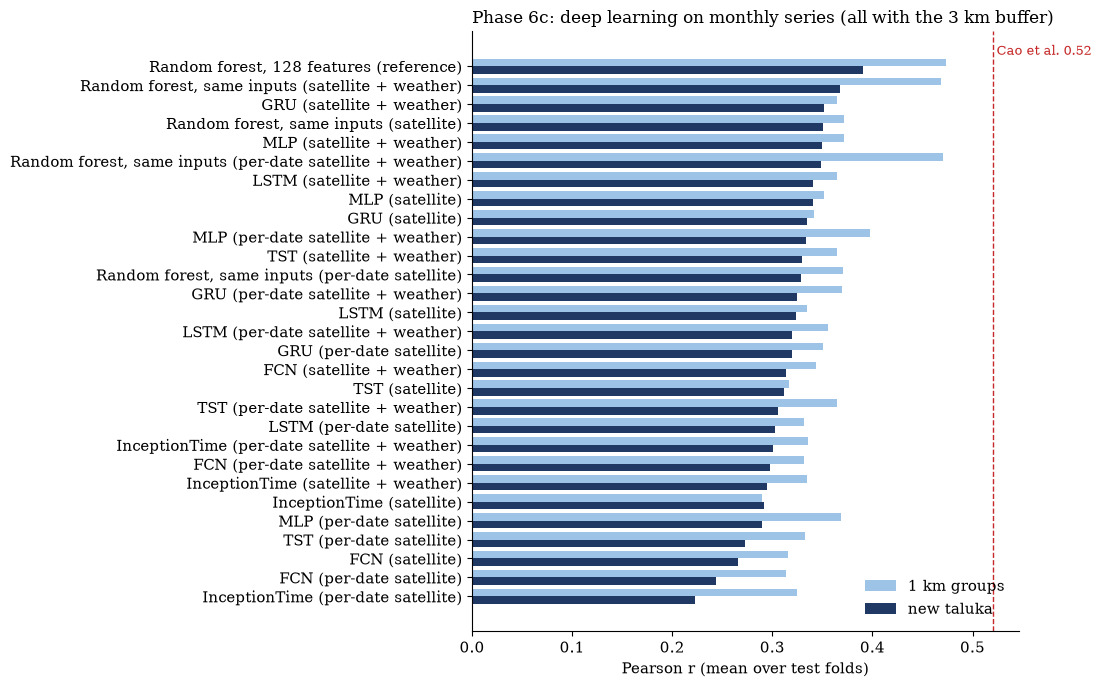

saved: ['P6c_experiments.csv', 'P6c_oof_predictions.csv', 'P6c_paired_tests.csv', 'P6c_training_log.csv']


In [8]:
# Step 6: figure, and save the out-of-fold predictions
order = EXP.sort_values("new taluka r", ascending=True)["experiment"]
fig, ax = plt.subplots(figsize=(11, 7)); yy = np.arange(len(order))
for off, col, lab, colr in [(0.2, "1 km groups r", "1 km groups", "#9DC3E6"), (-0.2, "new taluka r", "new taluka", "#1F3864")]:
    v = EXP.set_index("experiment").loc[order, col]; ax.barh(yy + off, v, 0.4, label=lab, color=colr)
ax.set_yticks(yy, order); ax.axvline(0.52, color="#C62828", ls="--", lw=1); ax.text(0.52, len(order) - 0.4, " Cao et al. 0.52", color="#C62828", fontsize=9)
ax.set_xlabel("Pearson r (mean over test folds)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Phase 6c: deep learning on monthly series (all with the 3 km buffer)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P6c_experiments.png", dpi=250, facecolor="white"); plt.show()
pd.concat([oof.assign(experiment=k) for k, (_, _, oof) in RES.items()]).to_csv(OUT / "P6c_oof_predictions.csv", index=False)
print("saved:", sorted(p.name for p in OUT.glob("P6c_*")))

## Summary

Deep learning from scratch does not help on this data. Six tsai networks on four versions of the season series (monthly or per-date, with or without weather) all stay below the Phase 6a random forest: best new taluka r = 0.352 (GRU) against 0.391, best 1 km groups r = 0.397 (MLP) against 0.473. They also stay below a random forest given exactly the same inputs, so the networks find nothing extra in the series. Weather helps every network, monthly series beat per-date series for new talukas (Sentinel-2 is too often missing per date), and time order adds little (the MLP matches LSTM and GRU). With fewer than 1,000 training fields the networks stop after 4 to 22 passes. **Decision:** keep the random forest as the reference; next deep learning tests bring in outside knowledge (Presto embeddings, physics-guided model).